In [3]:
%pip install opencv-python numpy matplotlib

  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/57/44/007b592809f50883c910db9ec4b81b16dfa0136407250fb581824daabf03/matplotlib-3.8.2-cp310-cp310-macosx_11_0_arm64.whl.metadata
  Obtaining dependency information for contourpy>=1.0.1 from https://files.pythonhosted.org/packages/fe/26/43821d61b7ee62c1809ec852bc572aaf4c27f101ebcebbbcce29a5ee0445/contourpy-1.2.0-cp310-cp310-macosx_11_0_arm64.whl.metadata
  Obtaining dependency information for cycler>=0.10 from https://files.pythonhosted.org/packages/e7/05/c19819d5e3d95294a6f5947fb9b9629efb316b96de511b418c53d245aae6/cycler-0.12.1-py3-none-any.whl.metadata
  Obtaining dependency information for fonttools>=4.22.0 from https://files.pythonhosted.org/packages/a7/b6/a3565ea582e243e58e30bb46029b34413aa7735ecce7d1fc7ae86721f9b7/fonttools-4.46.0-cp310-cp310-macosx_10_9_universal2.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.2/156.2 kB 2.5 MB/s eta 0:00:00a 0:00:01
  Obtaining dependency 

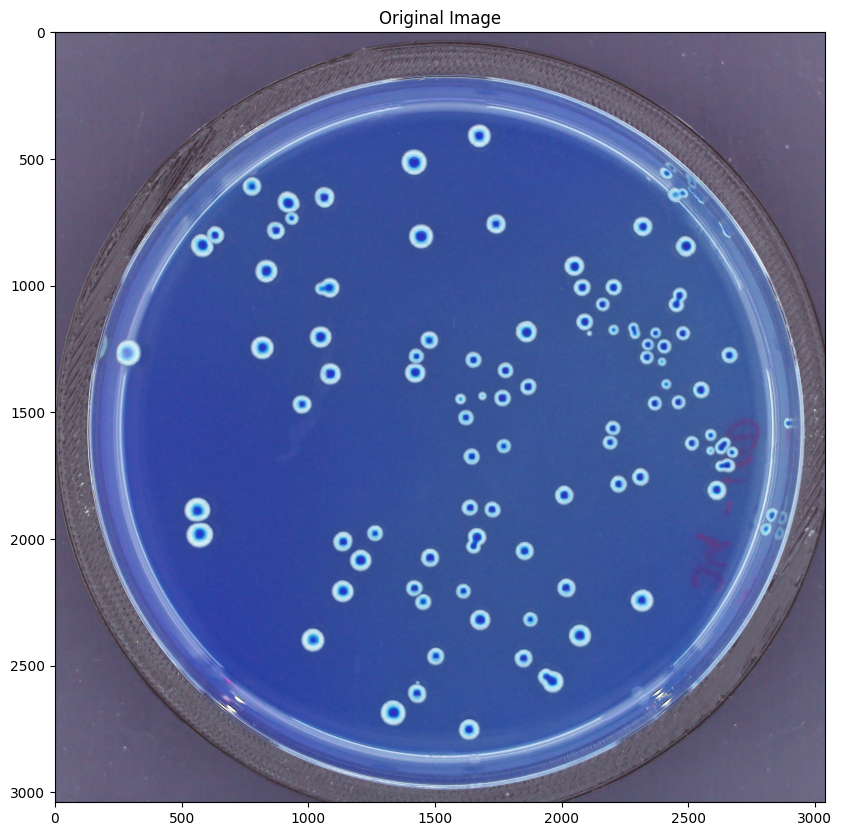

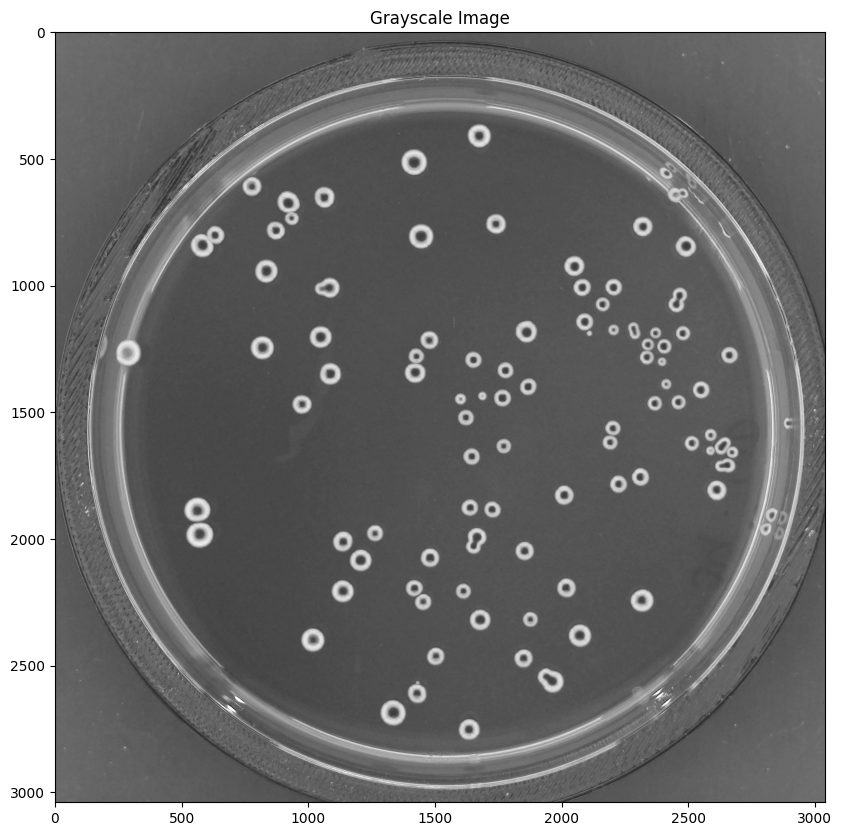

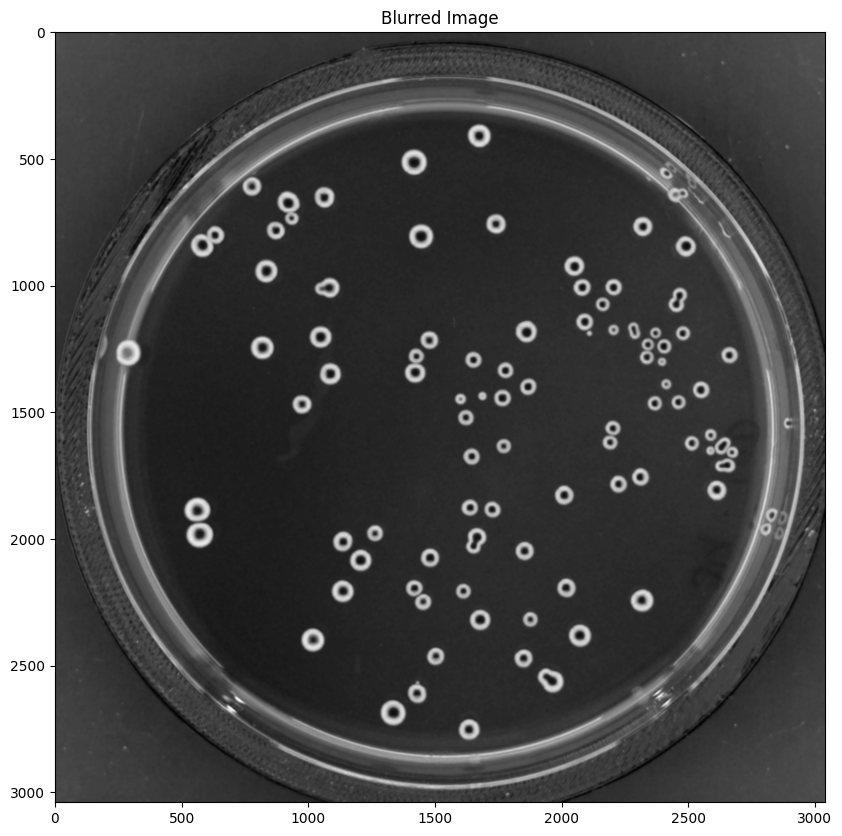

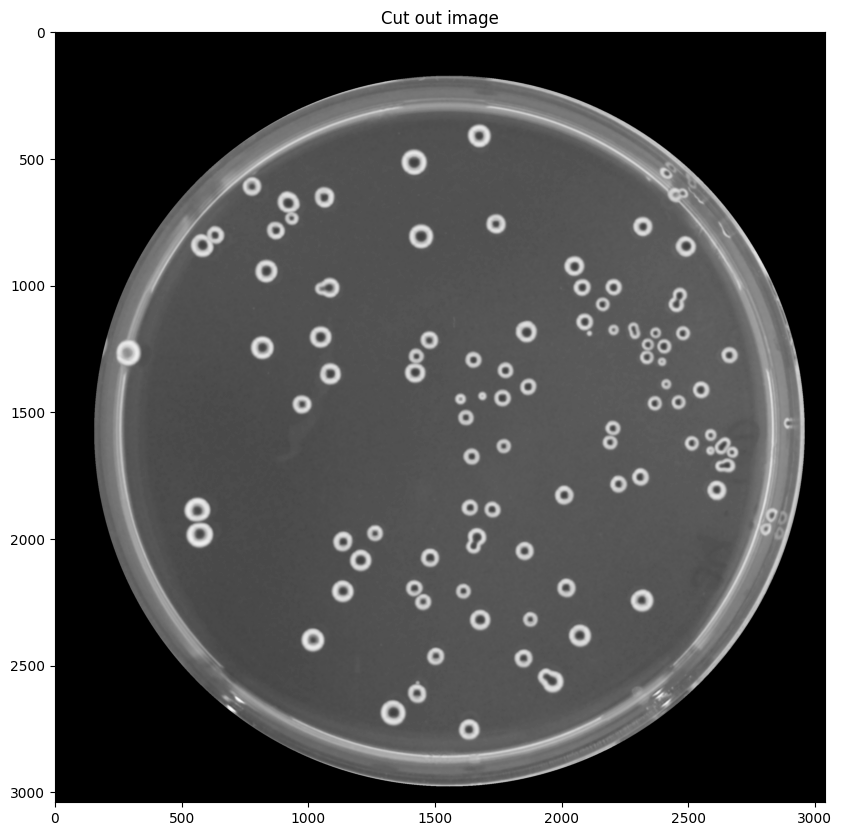

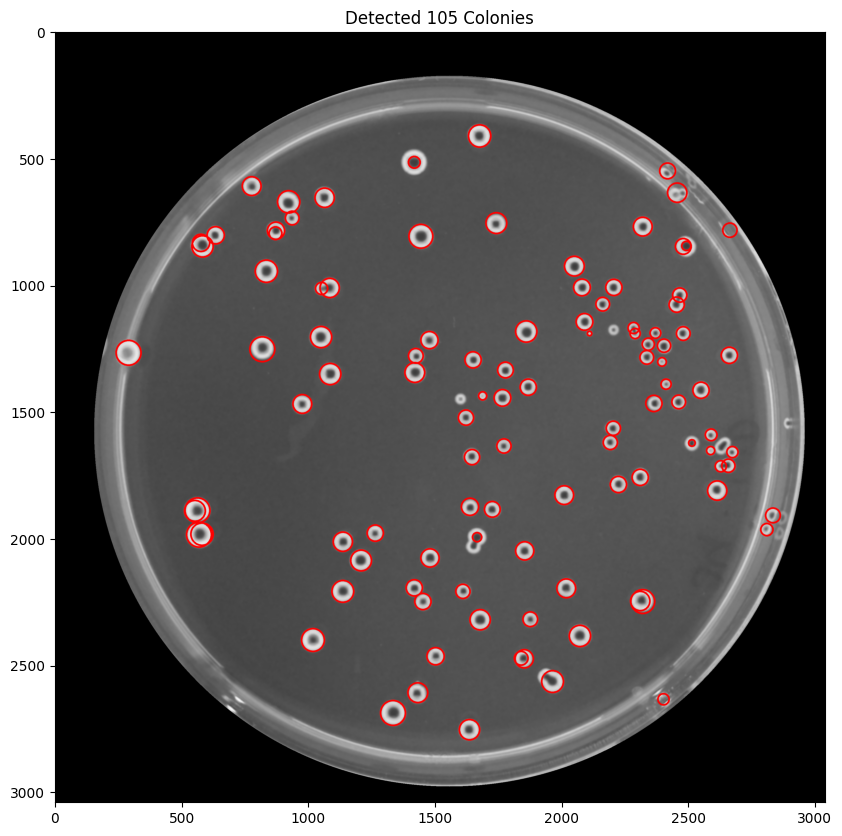

116

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


class Hyperparameters:
    def __init__(
        self,
        blur_kernel_size=15,
        blur_sigmax=0,
        outer_circle_param1=150,
        outer_circle_param2=10,
        colony_minDist=10,
        colony_param1=50,
        colony_param2=30,
        colony_minRadius=3,
        colony_maxRadius=50,
    ):
        self.blur_kernel_size = blur_kernel_size
        self.blur_sigmax = blur_sigmax
        self.outer_circle_param1 = outer_circle_param1
        self.outer_circle_param2 = outer_circle_param2
        self.colony_minDist = colony_minDist
        self.colony_param1 = colony_param1
        self.colony_param2 = colony_param2
        self.colony_minRadius = colony_minRadius
        self.colony_maxRadius = colony_maxRadius


def count_colonies(image_path, hyperparameters, debug=False):
    # Load the image
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title("Original Image")
        plt.show()

    height, width, channels = img.shape

    # Convert the image to grayscale for processing
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(gray, cmap="gray")
        plt.title("Grayscale Image")
        plt.show()

    # Use Gaussian blur to reduce noise and improve circle detection
    blurred = cv2.GaussianBlur(
        gray,
        (hyperparameters.blur_kernel_size, hyperparameters.blur_kernel_size),
        hyperparameters.blur_sigmax,
    )
    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title("Blurred Image")
        plt.show()

    # Hough Circle detection
    outer_circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=6,
        minDist=30,
        param1=hyperparameters.outer_circle_param1,
        param2=hyperparameters.outer_circle_param2,
        # Circle should be large, but not larger than the image.
        minRadius=round(max(height, width) / 3),
        maxRadius=round(max(height, width) / 2),
    )

    if outer_circles is not None:
        # Convert circles to expected format
        outer_circles = np.uint16(np.around(outer_circles))

        # Create a black mask
        mask = np.zeros_like(gray)

        # Get the (x, y) coordinate and the radius of the circle
        x, y, r = outer_circles[0][0]
        # r = r - 10  # Subtracting a value to remove the plastic border

        # Draw the circle in the mask
        cv2.circle(mask, (x, y), r, (255, 255, 255), -1)

        # Bitwise the image with mask
        result = cv2.bitwise_and(blurred, blurred, mask=mask)

        blurred = result

    if debug:
        plt.figure(figsize=(10, 10))
        plt.imshow(blurred, cmap="gray")
        plt.title("Cut out image")
        plt.show()

    # Detect circles in the image
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=hyperparameters.colony_minDist,
        param1=hyperparameters.colony_param1,
        param2=hyperparameters.colony_param2,
        minRadius=hyperparameters.colony_minRadius,
        maxRadius=hyperparameters.colony_maxRadius,
    )

    # If circles are detected, draw them on the grayscale image
    if circles is not None:
        circles = np.round(circles[0, :]).astype("int")
        if debug:
            output = cv2.cvtColor(
                blurred, cv2.COLOR_GRAY2RGB
            )  # Convert grayscale to RGB to draw in color
            for x, y, r in circles:
                cv2.circle(output, (x, y), r, (255, 0, 0), 6)  # Circle in red

            plt.figure(figsize=(10, 10))
            plt.imshow(output)
            plt.title(f"Detected {len(circles)} Colonies")
            plt.show()

        return round(len(circles) * 1.1)
    else:
        return 0


count_colonies(
    "../data/counted/cocci_aerococcus_viridans_34_default_mmrsbpb_4_18112022130303.jpg",
    Hyperparameters(),
    debug=True,
)

In [13]:
import time, csv, json
from IPython.display import clear_output


# https://mikulskibartosz.name/how-to-display-a-progress-bar-in-jupyter-notebook
def update_progress(progress):
    bar_length = 20
    if isinstance(progress, int):
        progress = float(progress)
    if not isinstance(progress, float):
        progress = 0
    if progress < 0:
        progress = 0
    if progress >= 1:
        progress = 1

    block = int(round(bar_length * progress))
    clear_output(wait=True)
    text = "Progress: [{0}] {1:.1f}%".format(
        "#" * block + "-" * (bar_length - block), progress * 100
    )
    print(text)


# Read the JSON file
with open("../data/counted/metadata.json", "r") as f:
    data = json.load(f)


def process_with_hyperparams(hyperparameters):
    results = []

    # Iterate through each element in the JSON array
    for i in range(len(data)):
        entry = data[i]
        file_name = entry.get("fileName")
        actual_count = entry.get("countedColonies")

        if file_name is not None and actual_count is not None:
            estimated_count = count_colonies(
                f"../data/counted/{file_name}", hyperparameters
            )

            results.append((file_name, estimated_count, actual_count))

    return results


# configurations = []

# for blur_kernel_size in [9, 15, 21]:
#     for blur_sigmax in [0]:
#         for outer_circle_param1 in [150]:
#             for outer_circle_param2 in [10]:
#                 for colony_minDist in [10]:
#                     for colony_param1 in [30, 50, 70]:
#                         for colony_param2 in [15, 30, 65]:
#                             for colony_minRadius in [3, 6]:
#                                 for colony_maxRadius in [50]:
#                                     configurations.append(
#                                         Hyperparameters(
#                                             blur_kernel_size,
#                                             blur_sigmax,
#                                             outer_circle_param1,
#                                             outer_circle_param2,
#                                             colony_minDist,
#                                             colony_param1,
#                                             colony_param2,
#                                             colony_minRadius,
#                                             colony_maxRadius,
#                                         )
#                                     )


def rel_diff(x, y):
    if y == 0 and x == 0:
        return 0
    elif y == 0:
        return 1
    else:
        return abs(x - y) / y


# # Open a CSV file for writing
# with open("timing_results.csv", "w", newline="") as csvfile:
#     csvwriter = csv.writer(csvfile)

#     # Write the header row
#     csvwriter.writerow(
#         [
#             "blur_kernel_size",
#             "blur_sigmax",
#             "outer_circle_param1",
#             "outer_circle_param2",
#             "colony_minDist",
#             "colony_param1",
#             "colony_param2",
#             "colony_minRadius",
#             "colony_maxRadius",
#             "mean_abs_diff",
#             "median_abs_diff",
#             "5th_percentile_abs_diff",
#             "95th_percentile_abs_diff",
#             "mean_rel_diff",
#             "median_rel_diff",
#             "5th_percentile_rel_diff",
#             "95th_percentile_rel_diff",
#         ]
#     )

#     for i in range(len(configurations)):
#         configuration = configurations[i]

#         start_time = time.time()

#         result = process_with_hyperparams(configuration)

#         end_time = time.time()

#         elapsed_time_ms = round((end_time - start_time) * 1000)

#         absolute_differences = [x[1] - x[2] for x in result]
#         absolute_differences.sort()

#         mean_abs_diff = np.mean(absolute_differences)
#         median_abs_diff = np.median(absolute_differences)
#         percentile_5th_abs_diff = np.percentile(absolute_differences, 5)
#         percentile_95th_abs_diff = np.percentile(absolute_differences, 95)

#         relative_differences = [rel_diff(x[1], x[2]) for x in result]
#         relative_differences.sort()

#         mean_rel_diff = np.mean(relative_differences)
#         median_rel_diff = np.median(relative_differences)
#         percentile_5th_rel_diff = np.percentile(relative_differences, 5)
#         percentile_95th_rel_diff = np.percentile(relative_differences, 95)

#         csvwriter.writerow(
#             [
#                 configuration.blur_kernel_size,
#                 configuration.blur_sigmax,
#                 configuration.outer_circle_param1,
#                 configuration.outer_circle_param2,
#                 configuration.colony_minDist,
#                 configuration.colony_param1,
#                 configuration.colony_param2,
#                 configuration.colony_minRadius,
#                 configuration.colony_maxRadius,
#                 mean_abs_diff,
#                 median_abs_diff,
#                 percentile_5th_abs_diff,
#                 percentile_95th_abs_diff,
#                 mean_rel_diff,
#                 median_rel_diff,
#                 percentile_5th_rel_diff,
#                 percentile_95th_rel_diff,
#             ]
#         )

#         update_progress((i + 1) / len(configurations))

In [14]:
start_time = time.time()

result = process_with_hyperparams(Hyperparameters())

end_time = time.time()

elapsed_time_ms = round((end_time - start_time) * 1000)

absolute_differences = [x[1] - x[2] for x in result]
absolute_differences.sort()

mean_abs_diff = np.mean(absolute_differences)
median_abs_diff = np.median(absolute_differences)
percentile_5th_abs_diff = np.percentile(absolute_differences, 5)
percentile_95th_abs_diff = np.percentile(absolute_differences, 95)

relative_differences = [rel_diff(x[1], x[2]) for x in result]
relative_differences.sort()

mean_rel_diff = np.mean(relative_differences)
median_rel_diff = np.median(relative_differences)
percentile_5th_rel_diff = np.percentile(relative_differences, 5)
percentile_95th_rel_diff = np.percentile(relative_differences, 95)

print(f"Elapsed time: {elapsed_time_ms} ms")
print(f"Mean absolute difference: {mean_abs_diff}")
print(f"Median absolute difference: {median_abs_diff}")

print(f"Mean relative difference: {mean_rel_diff}")
print(f"Median relative difference: {median_rel_diff}")

Elapsed time: 21473 ms
Mean absolute difference: -100.33333333333333
Median absolute difference: 0.0
Mean relative difference: 0.2110380857997012
Median relative difference: 0.08733790999237223
